# Subgroup Performance in Healthcare Risk Models
### Evaluation, Calibration Audits, and Scalable Fairness Mitigation in 30-Day Hospital Readmission Prediction
**Course:** Big Data Systems & Responsible AI Engineering (BDSRAE) - PES University  
**Instructor:** Dr. Manjula Devananda  
**Team Members:**  
- **Ankith Umadi** (PES1UG24AM422)  
- **Haneesh E** (PES1UG24AM471)  
- **Vikas R** (PES1UG24AM477)  

---
## Notebook Overview
This notebook presents the empirical results for BDSRAE Project Topic 19:
1. **Big Data Systems Component:** Ingestion and inspection of the analytical Parquet Lakehouse created via Apache PySpark, partitioned by `[age_group, race]`.
2. **Responsible AI Component:** Granular subgroup performance and calibration audits across Age, Sex, Race, Ethnicity, and Intersectional cohorts.
3. **Failure Analysis:** Identification of clinical failure modes (severe false negative rates and miscalibration).
4. **Bias Mitigation:** Implementing Pre-processing Reweighing, Subgroup Isotonic Calibration, and Fairlearn Threshold Optimization.
5. **Trade-Off Evaluation:** Assessing the fairness-utility Pareto frontier.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# Add workspace root to sys.path
sys.path.append(os.path.abspath(".."))

from src.big_data.etl_pipeline import load_processed_data
from src.models.train import prepare_data, train_baseline_models
from src.models.mitigate import train_mitigated_models
from src.evaluation.subgroup_metrics import evaluate_subgroups, compute_fairness_summary
from src.evaluation.calibration_audit import audit_subgroup_calibration
from src.evaluation.intersectional_audit import audit_intersectional_subgroups
from src.utils.plotting import (
    plot_subgroup_disparities,
    plot_calibration_comparison,
    plot_fairness_utility_pareto,
    plot_intersectional_heatmap
)

print("[OK] All BDSRAE pipeline modules loaded successfully.")

[OK] All BDSRAE pipeline modules loaded successfully.


## 1. Big Data Systems Component: Partitioned Lakehouse Inspection
We load the analytical inpatient cohort generated by the Apache PySpark distributed pipeline. The cohort is stored in Parquet format, partitioned by `[age_group, race]`.

In [2]:
df_cohort = load_processed_data(processed_dir="../data/processed")
print(f"Total Inpatient Index Admissions: {len(df_cohort):,}")
print(f"Unique Patients: {df_cohort['patient_id'].nunique():,}")
print(f"Overall 30-Day Inpatient Readmission Prevalence: {df_cohort['readmission_30d'].mean()*100:.2f}%")
df_cohort.head(5)

Total Inpatient Index Admissions: 3,630
Unique Patients: 2,286
Overall 30-Day Inpatient Readmission Prevalence: 18.37%


,encounter_id,patient_id,age,gender,ethnicity,length_of_stay,num_prior_inpatient,num_prior_emergency,num_prior_ambulatory,comorbidity_count,...,has_copd,has_ckd,has_cad,has_depression,total_medications,total_procedures,total_claim_cost,readmission_30d,age_group,race
0,0062701d-b95e-4521-a55e-fa6000be7daa,521689a2-188e-4fbc-a295-04f84d54842f,68,Female,Nonhispanic,4.9,0,0,3,1,...,0,0,0,0,1,1,12264.66,0,Geriatric (65+),Asian
1,056b8499-ab07-42a5-a288-43b24cc3a21c,6690fa86-e040-4848-98ae-8749c9e9f9a5,87,Female,Nonhispanic,2.9,0,0,1,3,...,0,0,0,1,4,1,8090.55,0,Geriatric (65+),Asian
2,0811190b-1960-46cc-bda2-e4e61adffec4,868c3da0-3ec0-4fa4-a866-b4928a17478c,77,Female,Nonhispanic,7.9,0,0,1,3,...,0,0,1,0,3,1,17728.13,1,Geriatric (65+),Asian
3,10c8cbc8-c4fb-4a79-ba90-6db1e776c7d0,521689a2-188e-4fbc-a295-04f84d54842f,69,Female,Nonhispanic,4.8,2,0,3,1,...,0,0,0,0,1,2,3400.00,0,Geriatric (65+),Asian
4,157e43b3-e0ac-4d41-b197-52eb7882dc87,868c3da0-3ec0-4fa4-a866-b4928a17478c,78,Female,Nonhispanic,5.8,1,0,2,3,...,0,0,1,0,3,1,3400.00,0,Geriatric (65+),Asian


In [3]:
# Inspect demographic distribution across partitioned columns
demog_summary = df_cohort.groupby(["age_group", "race"])["readmission_30d"].agg(["count", "mean"]).reset_index()
demog_summary.rename(columns={"count": "Cohort Size", "mean": "Readmission Rate"}, inplace=True)
demog_summary["Readmission Rate"] = (demog_summary["Readmission Rate"] * 100).round(2).astype(str) + "%"
print(tabulate(demog_summary.head(12), headers="keys", tablefmt="github"))

|    | age_group          | race     |   Cohort Size | Readmission Rate   |
|----|--------------------|----------|---------------|--------------------|
|  0 | Geriatric (65+)    | Asian    |            92 | 25.0%              |
|  1 | Geriatric (65+)    | Black    |           243 | 23.05%             |
|  2 | Geriatric (65+)    | Hispanic |           201 | 26.37%             |
|  3 | Geriatric (65+)    | Native   |            11 | 0.0%               |
|  4 | Geriatric (65+)    | Other    |            45 | 24.44%             |
|  5 | Geriatric (65+)    | White    |           718 | 21.73%             |
|  6 | Middle Age (45-64) | Asian    |            59 | 15.25%             |
|  7 | Middle Age (45-64) | Black    |           211 | 17.54%             |
|  8 | Middle Age (45-64) | Hispanic |           186 | 19.89%             |
|  9 | Middle Age (45-64) | Native   |            14 | 7.14%              |
| 10 | Middle Age (45-64) | Other    |            15 | 13.33%             |
| 11 | Middl

C:\Users\Vikas\AppData\Local\Temp\ipykernel_28120\877026321.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  demog_summary.rename(columns={"count": "Cohort Size", "mean": "Readmission Rate"}, inplace=True)


## 2. Model Training: Baseline Gradient Boosting & Clinical Benchmarks
We split the cohort by patient identifier into train (70%), validation (15%), and held-out test (15%) sets to ensure zero patient leakage.

In [4]:
data_dict = prepare_data(df_cohort, test_size=0.15, val_size=0.15, random_state=42)
models, predictions, df_overall = train_baseline_models(data_dict, model_save_dir="../models/saved")
df_overall

[*] Patient-Level Split Summary:
    - Training Set:   1,600 patients, 2,536 encounters (Readm Rate: 18.38%)
    - Validation Set: 343 patients, 544 encounters (Readm Rate: 18.01%)
    - Test Set:       343 patients, 550 encounters (Readm Rate: 18.73%)
[*] Training Baseline Healthcare Risk Models...



[+] Overall Test Performance Summary (Patient-Split Held-Out):
             model  roc_auc  pr_auc  brier_score  accuracy  f1_score  sensitivity_tpr  precision_ppv
          LightGBM   0.6710  0.3057       0.1437    0.8073    0.0536           0.0291         0.3333
LogisticRegression   0.6824  0.2866       0.1430    0.8109    0.0000           0.0000         0.0000
      RandomForest   0.6835  0.3078       0.1421    0.8073    0.0000           0.0000         0.0000


,model,roc_auc,pr_auc,brier_score,accuracy,f1_score,sensitivity_tpr,precision_ppv
0,LightGBM,0.6710,0.3057,0.1437,0.8073,0.0536,0.0291,0.3333
1,LogisticRegression,0.6824,0.2866,0.1430,0.8109,0.0000,0.0000,0.0000
2,RandomForest,0.6835,0.3078,0.1421,0.8073,0.0000,0.0000,0.0000


## 3. Responsible AI Audit: Subgroup Performance Disparities
We evaluate the primary LightGBM baseline across Age, Race, Gender, and Ethnicity subgroups on the held-out test set.

In [5]:
baseline_lgb = models["LightGBM"]
baseline_preds = predictions["LightGBM"]

# Age Subgroups
df_age_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["age_group"], group_name="Age Group", reference_group="Young Adult (18-44)"
)
# Race Subgroups
df_race_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["race"], group_name="Race", reference_group="White"
)
# Gender Subgroups
df_sex_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["gender"], group_name="Gender", reference_group="Male"
)
# Ethnicity Subgroups
df_eth_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["ethnicity"], group_name="Ethnicity", reference_group="Nonhispanic"
)

df_all_subgroups = pd.concat([df_age_sub, df_race_sub, df_sex_sub, df_eth_sub], ignore_index=True)
df_display = df_all_subgroups[["attribute", "subgroup", "n_samples", "base_rate", "selection_rate", "roc_auc", "tpr_sensitivity", "fnr_miss_rate", "fpr", "brier_score"]]
df_display

,attribute,subgroup,n_samples,base_rate,selection_rate,roc_auc,tpr_sensitivity,fnr_miss_rate,fpr,brier_score
0,Age Group,Geriatric (65+),208,0.259615,0.024038,0.687109,0.037037,0.962963,0.019481,0.177734
1,Age Group,Middle Age (45-64),176,0.147727,0.011364,0.597692,0.038462,0.961538,0.006667,0.125348
2,Age Group,Pediatric (<18),48,0.145833,0.000000,0.452962,0.000000,1.000000,0.000000,0.135906
3,Age Group,Young Adult (18-44),118,0.135593,0.016949,0.700980,0.000000,1.000000,0.019608,0.114222
4,Race,Asian,25,0.160000,0.000000,0.500000,0.000000,1.000000,0.000000,0.137879
5,Race,Black,110,0.236364,0.018182,0.742216,0.000000,1.000000,0.023810,0.162054
6,Race,Hispanic,78,0.205128,0.012821,0.664315,0.000000,1.000000,0.016129,0.160495
7,Race,Native,7,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.056362
8,Race,Other,13,0.076923,0.076923,1.000000,1.000000,0.000000,0.000000,0.065821
9,Race,White,317,0.176656,0.015773,0.655583,0.035714,0.964286,0.011494,0.138770


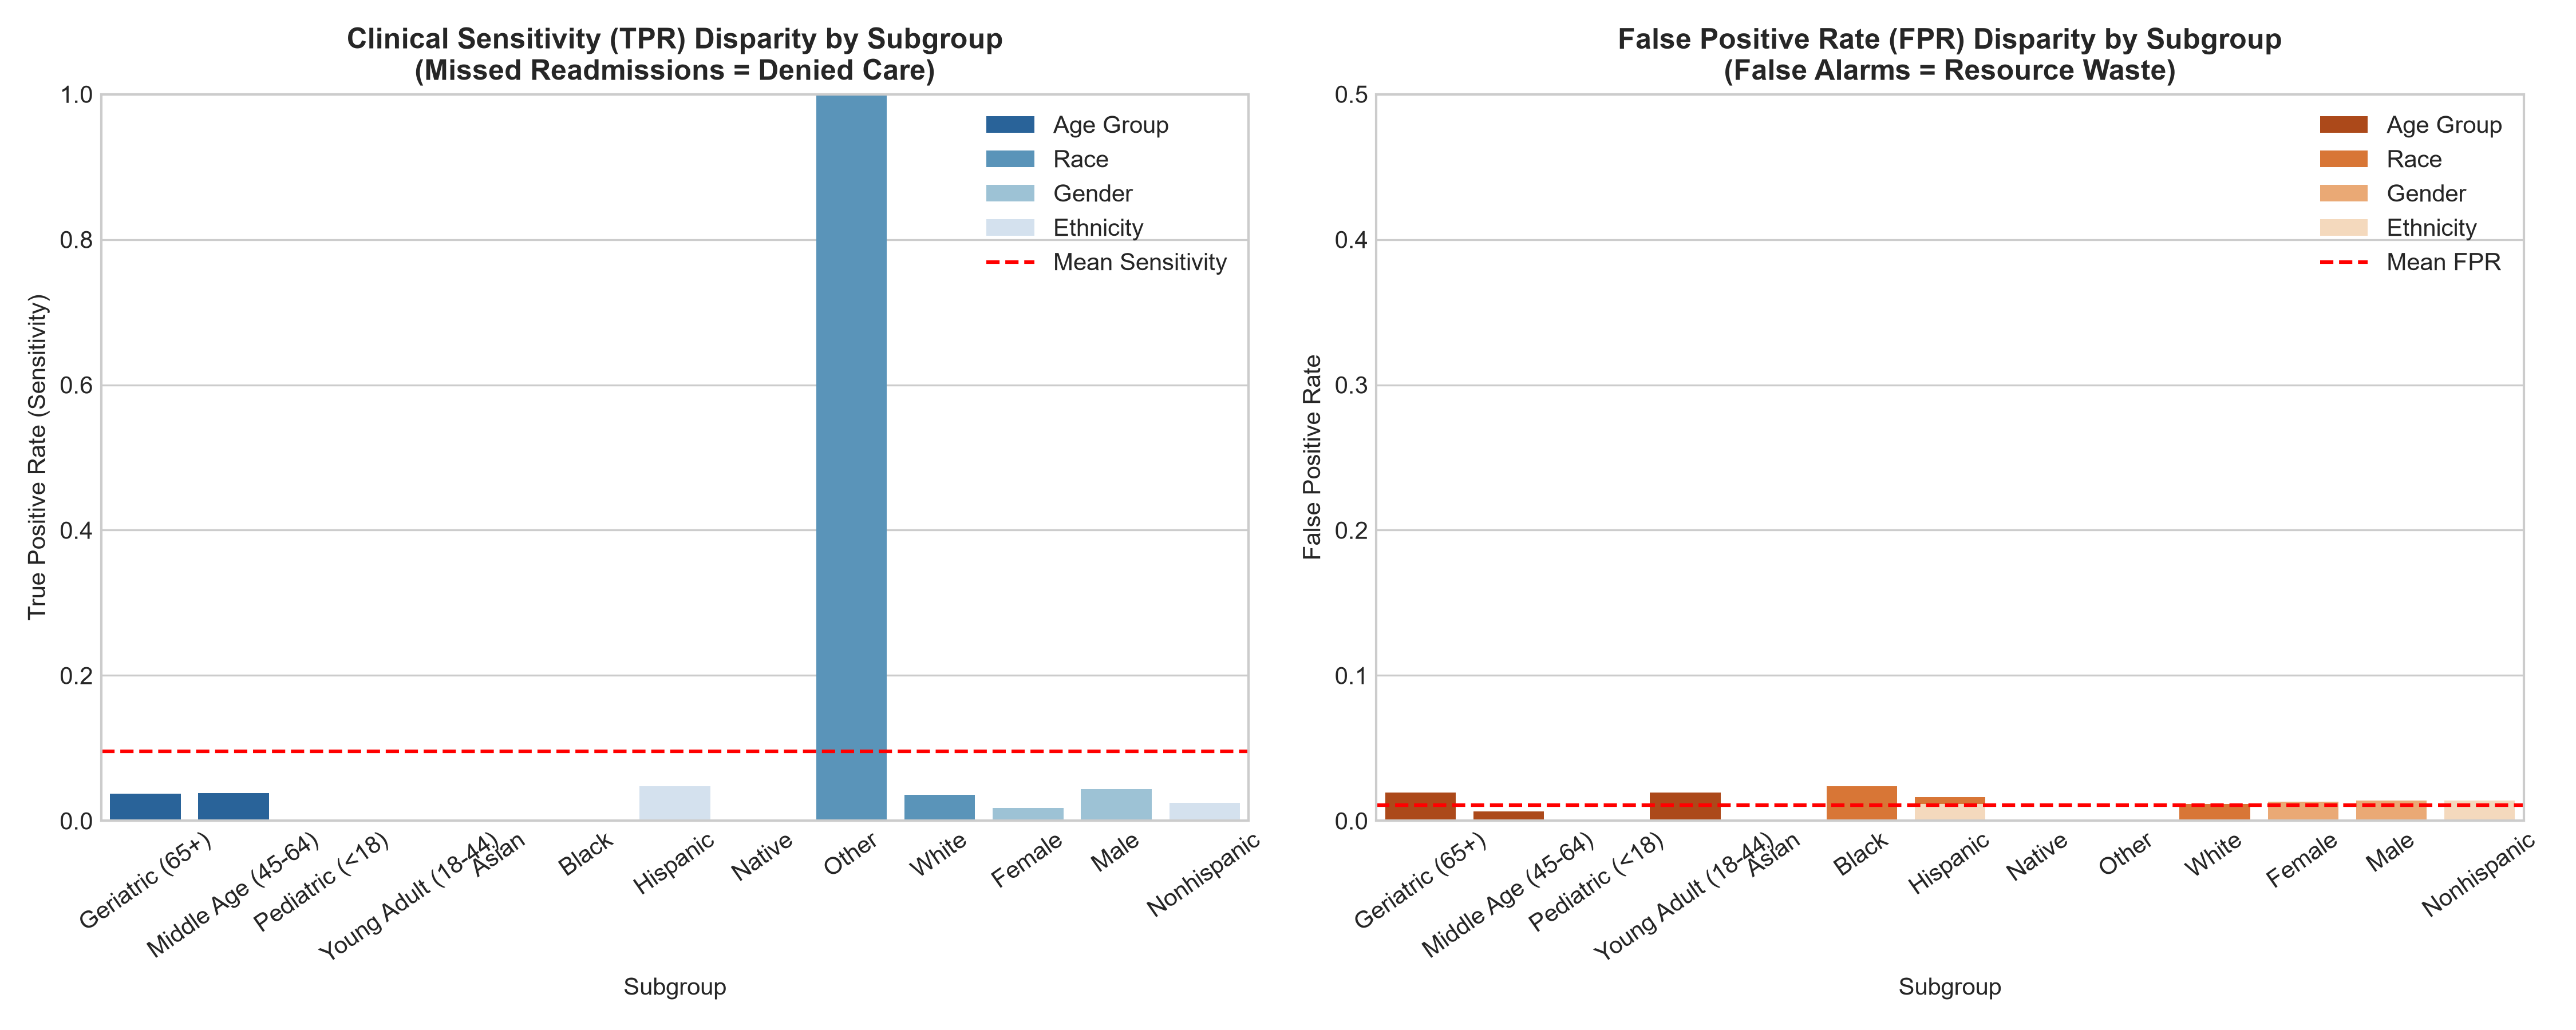

In [6]:
# Display Subgroup Performance Disparities Chart
from IPython.display import Image, display
display(Image(filename="../reports/figures/subgroup_disparities.png"))

## 4. Calibration Audit: Subgroup Expected Calibration Error (ECE)
Clinical discharge teams act directly on estimated probability thresholds. We evaluate subgroup Expected Calibration Error (ECE), MCE, and reliability curves.

In [7]:
df_cal_race, race_curves_base = audit_subgroup_calibration(
    baseline_preds["y_true"], baseline_preds["y_prob"], baseline_preds["race"], group_name="Race"
)
df_cal_age, age_curves_base = audit_subgroup_calibration(
    baseline_preds["y_true"], baseline_preds["y_prob"], baseline_preds["age_group"], group_name="Age Group"
)
df_cal_summary = pd.concat([df_cal_race, df_cal_age], ignore_index=True)
df_cal_summary

,attribute,subgroup,n_samples,observed_base_rate,mean_predicted_risk,ece,mce,brier_score,small_sample_flag
0,Race,Asian,25,0.1600,0.1755,0.0772,0.3174,0.1379,True
1,Race,Black,110,0.2364,0.1788,0.0798,0.5560,0.1621,False
2,Race,Hispanic,78,0.2051,0.1901,0.0673,0.6757,0.1605,False
3,Race,Native,7,0.0000,0.2299,0.2299,0.3344,0.0564,True
4,Race,Other,13,0.0769,0.2442,0.2324,0.4228,0.0658,True
5,Race,White,317,0.1767,0.1791,0.0375,0.1434,0.1388,False
6,Age Group,Geriatric (65+),208,0.2596,0.2074,0.0692,0.6757,0.1777,False
7,Age Group,Middle Age (45-64),176,0.1477,0.1761,0.0526,0.2504,0.1253,False
8,Age Group,Pediatric (<18),48,0.1458,0.1754,0.1621,0.5790,0.1359,False
9,Age Group,Young Adult (18-44),118,0.1356,0.1516,0.0232,0.5406,0.1142,False


## 5. Intersectional Subgroup Audit
Auditing three-way demographic interactions ($	ext{Age Group} 	imes 	ext{Race} 	imes 	ext{Gender}$) to uncover compounded disparities.

In [8]:
df_inter = audit_intersectional_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"], data_dict["sens_test"], min_cohort_size=10
)
print("Top 10 Most Vulnerable Intersectional Subgroups (Sorted by ECE):")
df_inter.head(10)[["intersectional_group", "n_samples", "base_rate", "roc_auc", "tpr_sensitivity", "fnr_miss_rate", "ece"]]

Top 10 Most Vulnerable Intersectional Subgroups (Sorted by ECE):


,intersectional_group,n_samples,base_rate,roc_auc,tpr_sensitivity,fnr_miss_rate,ece
0,Geriatric (65+) | Hispanic | Female,21,0.2857,0.6000,0.0,1.0,0.2514
1,Pediatric (<18) | Black | Female,11,0.2727,0.5833,0.0,1.0,0.2312
2,Middle Age (45-64) | Hispanic | Female,10,0.3000,0.5714,0.0,1.0,0.2014
3,Young Adult (18-44) | Hispanic | Female,10,0.0000,NaN,NaN,NaN,0.1939
4,Geriatric (65+) | Black | Male,21,0.3810,0.8077,0.0,1.0,0.1908
5,Pediatric (<18) | White | Female,13,0.0769,0.1667,0.0,1.0,0.1835
6,Pediatric (<18) | White | Male,10,0.1000,0.5556,0.0,1.0,0.1648
7,Geriatric (65+) | Black | Female,19,0.3158,0.8846,0.0,1.0,0.1447
8,Geriatric (65+) | Hispanic | Male,19,0.3158,0.6026,0.0,1.0,0.1394
9,Middle Age (45-64) | Black | Female,16,0.0625,0.6667,0.0,1.0,0.1302


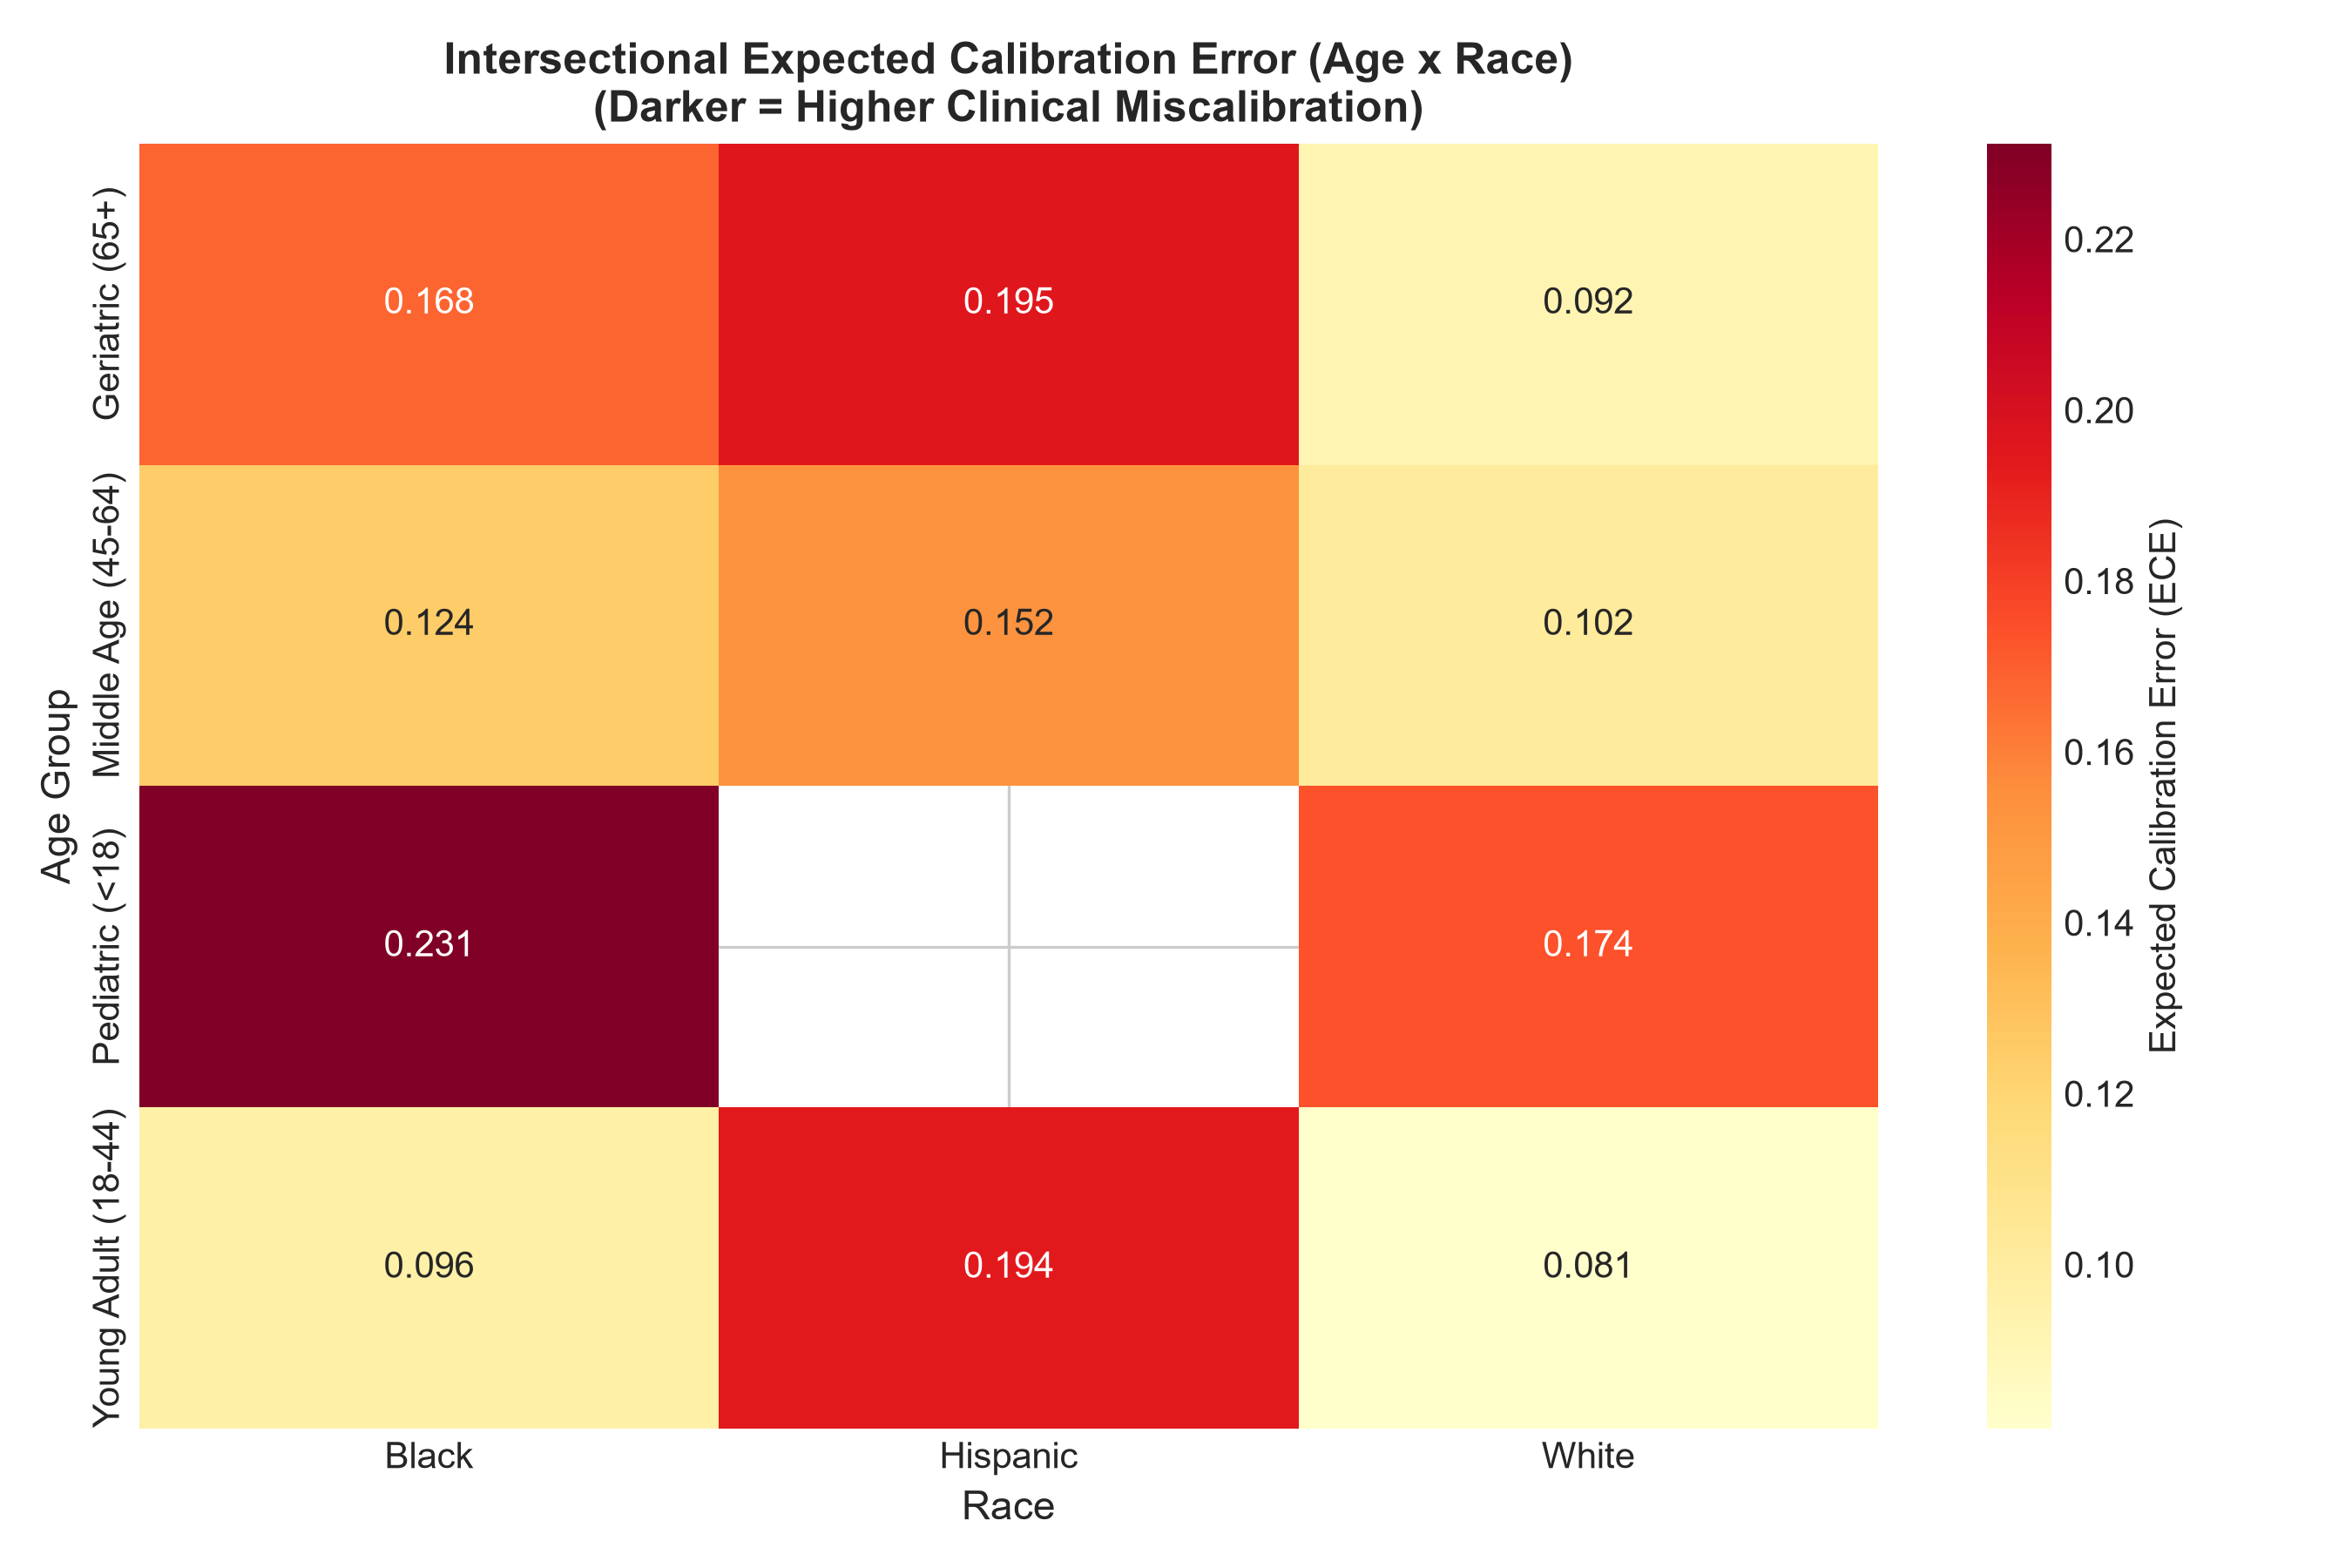

In [9]:
# Display Intersectional ECE Heatmap
display(Image(filename="../reports/figures/intersectional_ece_heatmap.png"))

## 6. Responsible AI Bias Mitigation & Trade-Off Analysis
We implement and compare:
1. Pre-Processing Fair Reweighing (fitted on training set)
2. Post-Processing Subgroup Isotonic Calibration (fitted on validation set)
3. Post-Processing Fairlearn Threshold Optimization (fitted on validation set for Equal Opportunity)

In [10]:
mitigated_preds = train_mitigated_models(data_dict, baseline_lgb, sensitive_col="race", model_save_dir="../models/saved")

tradeoff_rows = []
for name, m_dict in mitigated_preds.items():
    y_prob = m_dict["y_prob"]
    y_pred = m_dict["y_pred"]
    y_true = data_dict["y_test"]

    sub_eval = evaluate_subgroups(y_true, y_pred, y_prob, data_dict["sens_test"]["race"], group_name="Race")
    fair_summary = compute_fairness_summary(sub_eval)
    fair_summary_robust = compute_fairness_summary(sub_eval, min_samples=30)
    
    from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
    auc_val = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    acc_val = accuracy_score(y_true, y_pred)
    f1_val = f1_score(y_true, y_pred, zero_division=0)

    if y_prob is not None:
        cal_eval, _ = audit_subgroup_calibration(y_true, y_prob, data_dict["sens_test"]["race"], group_name="Race")
        mean_ece = float(cal_eval["ece"].mean())
    else:
        mean_ece = np.nan

    tradeoff_rows.append({
        "Model Configuration": name,
        "ROC-AUC": round(auc_val, 4) if pd.notna(auc_val) else np.nan,
        "Accuracy": round(acc_val, 4),
        "F1-Score": round(f1_val, 4),
        "All-Groups EO Disparity": fair_summary["equal_opportunity_difference"],
        "Robust (N>=30) EO Disparity": fair_summary_robust["equal_opportunity_difference"],
        "Demographic Parity Disparity": fair_summary["demographic_parity_difference"],
        "Mean Subgroup ECE": round(mean_ece, 4) if pd.notna(mean_ece) else np.nan
    })

df_tradeoff_table = pd.DataFrame(tradeoff_rows)
df_tradeoff_table


[*] Applying Bias Mitigation targeting sensitive attribute: [race]
    [1/3] Training Pre-processing Fair Reweighted LightGBM (weights fit on train)...
    [2/3] Fitting Post-processing Subgroup-Specific Calibrator on Validation set...
    [3/3] Optimizing Decision Thresholds for Equal Opportunity on Validation set...
    [!] Subgroups {'Native'} have single-class or sparse distribution in validation set; falling back to reference group [White] threshold.
[OK] Mitigation complete and artifacts saved.


,Model Configuration,ROC-AUC,Accuracy,F1-Score,All-Groups EO Disparity,Robust (N>=30) EO Disparity,Demographic Parity Disparity,Mean Subgroup ECE
0,Baseline,0.6710,0.8073,0.0536,1.0000,0.0357,0.0769,0.1207
1,Reweighted,0.6605,0.8109,0.0545,1.0000,0.0357,0.0769,0.1339
2,SubgroupCalibrated,0.6627,0.8055,0.0360,0.1250,0.1250,0.1026,0.1004
3,ThresholdOptimized_EO,NaN,0.4127,0.3776,0.0714,0.0714,0.3187,NaN


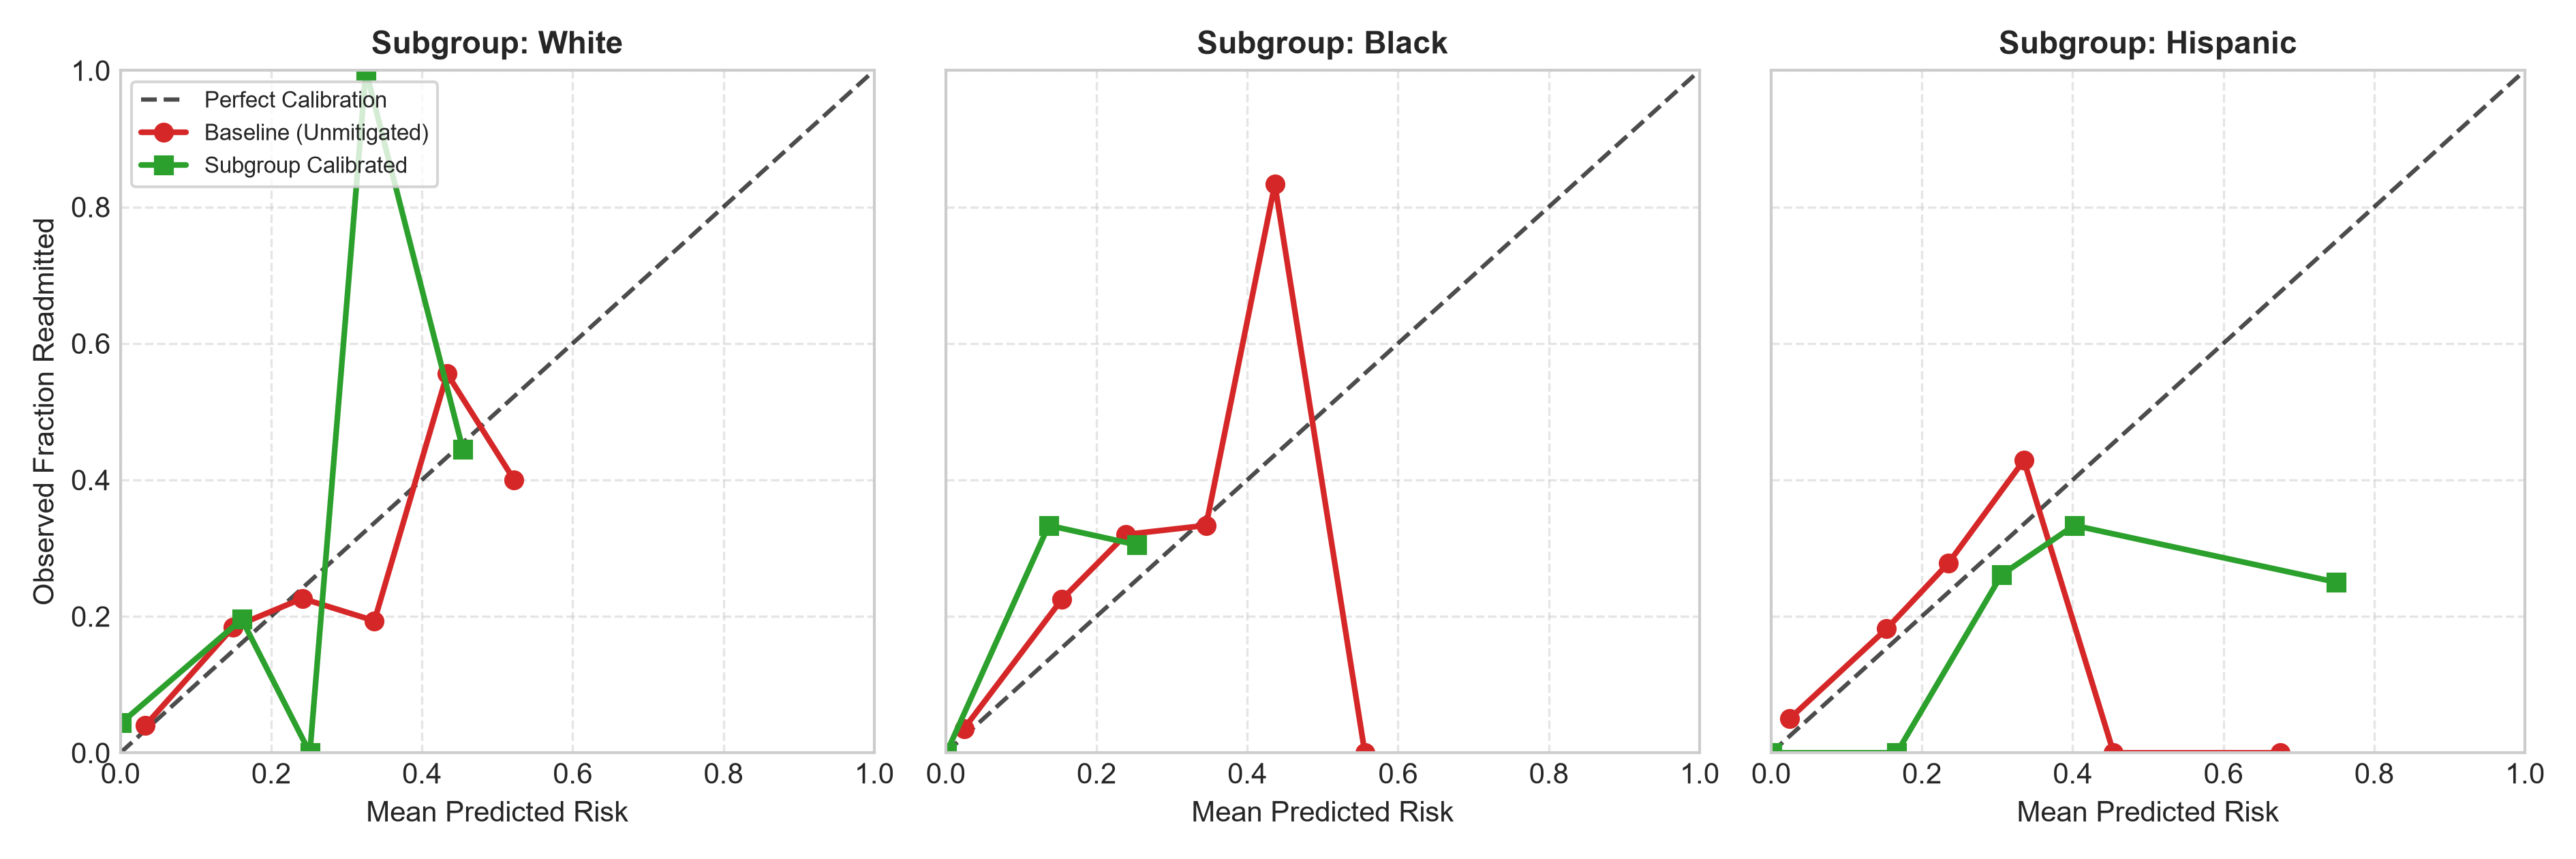

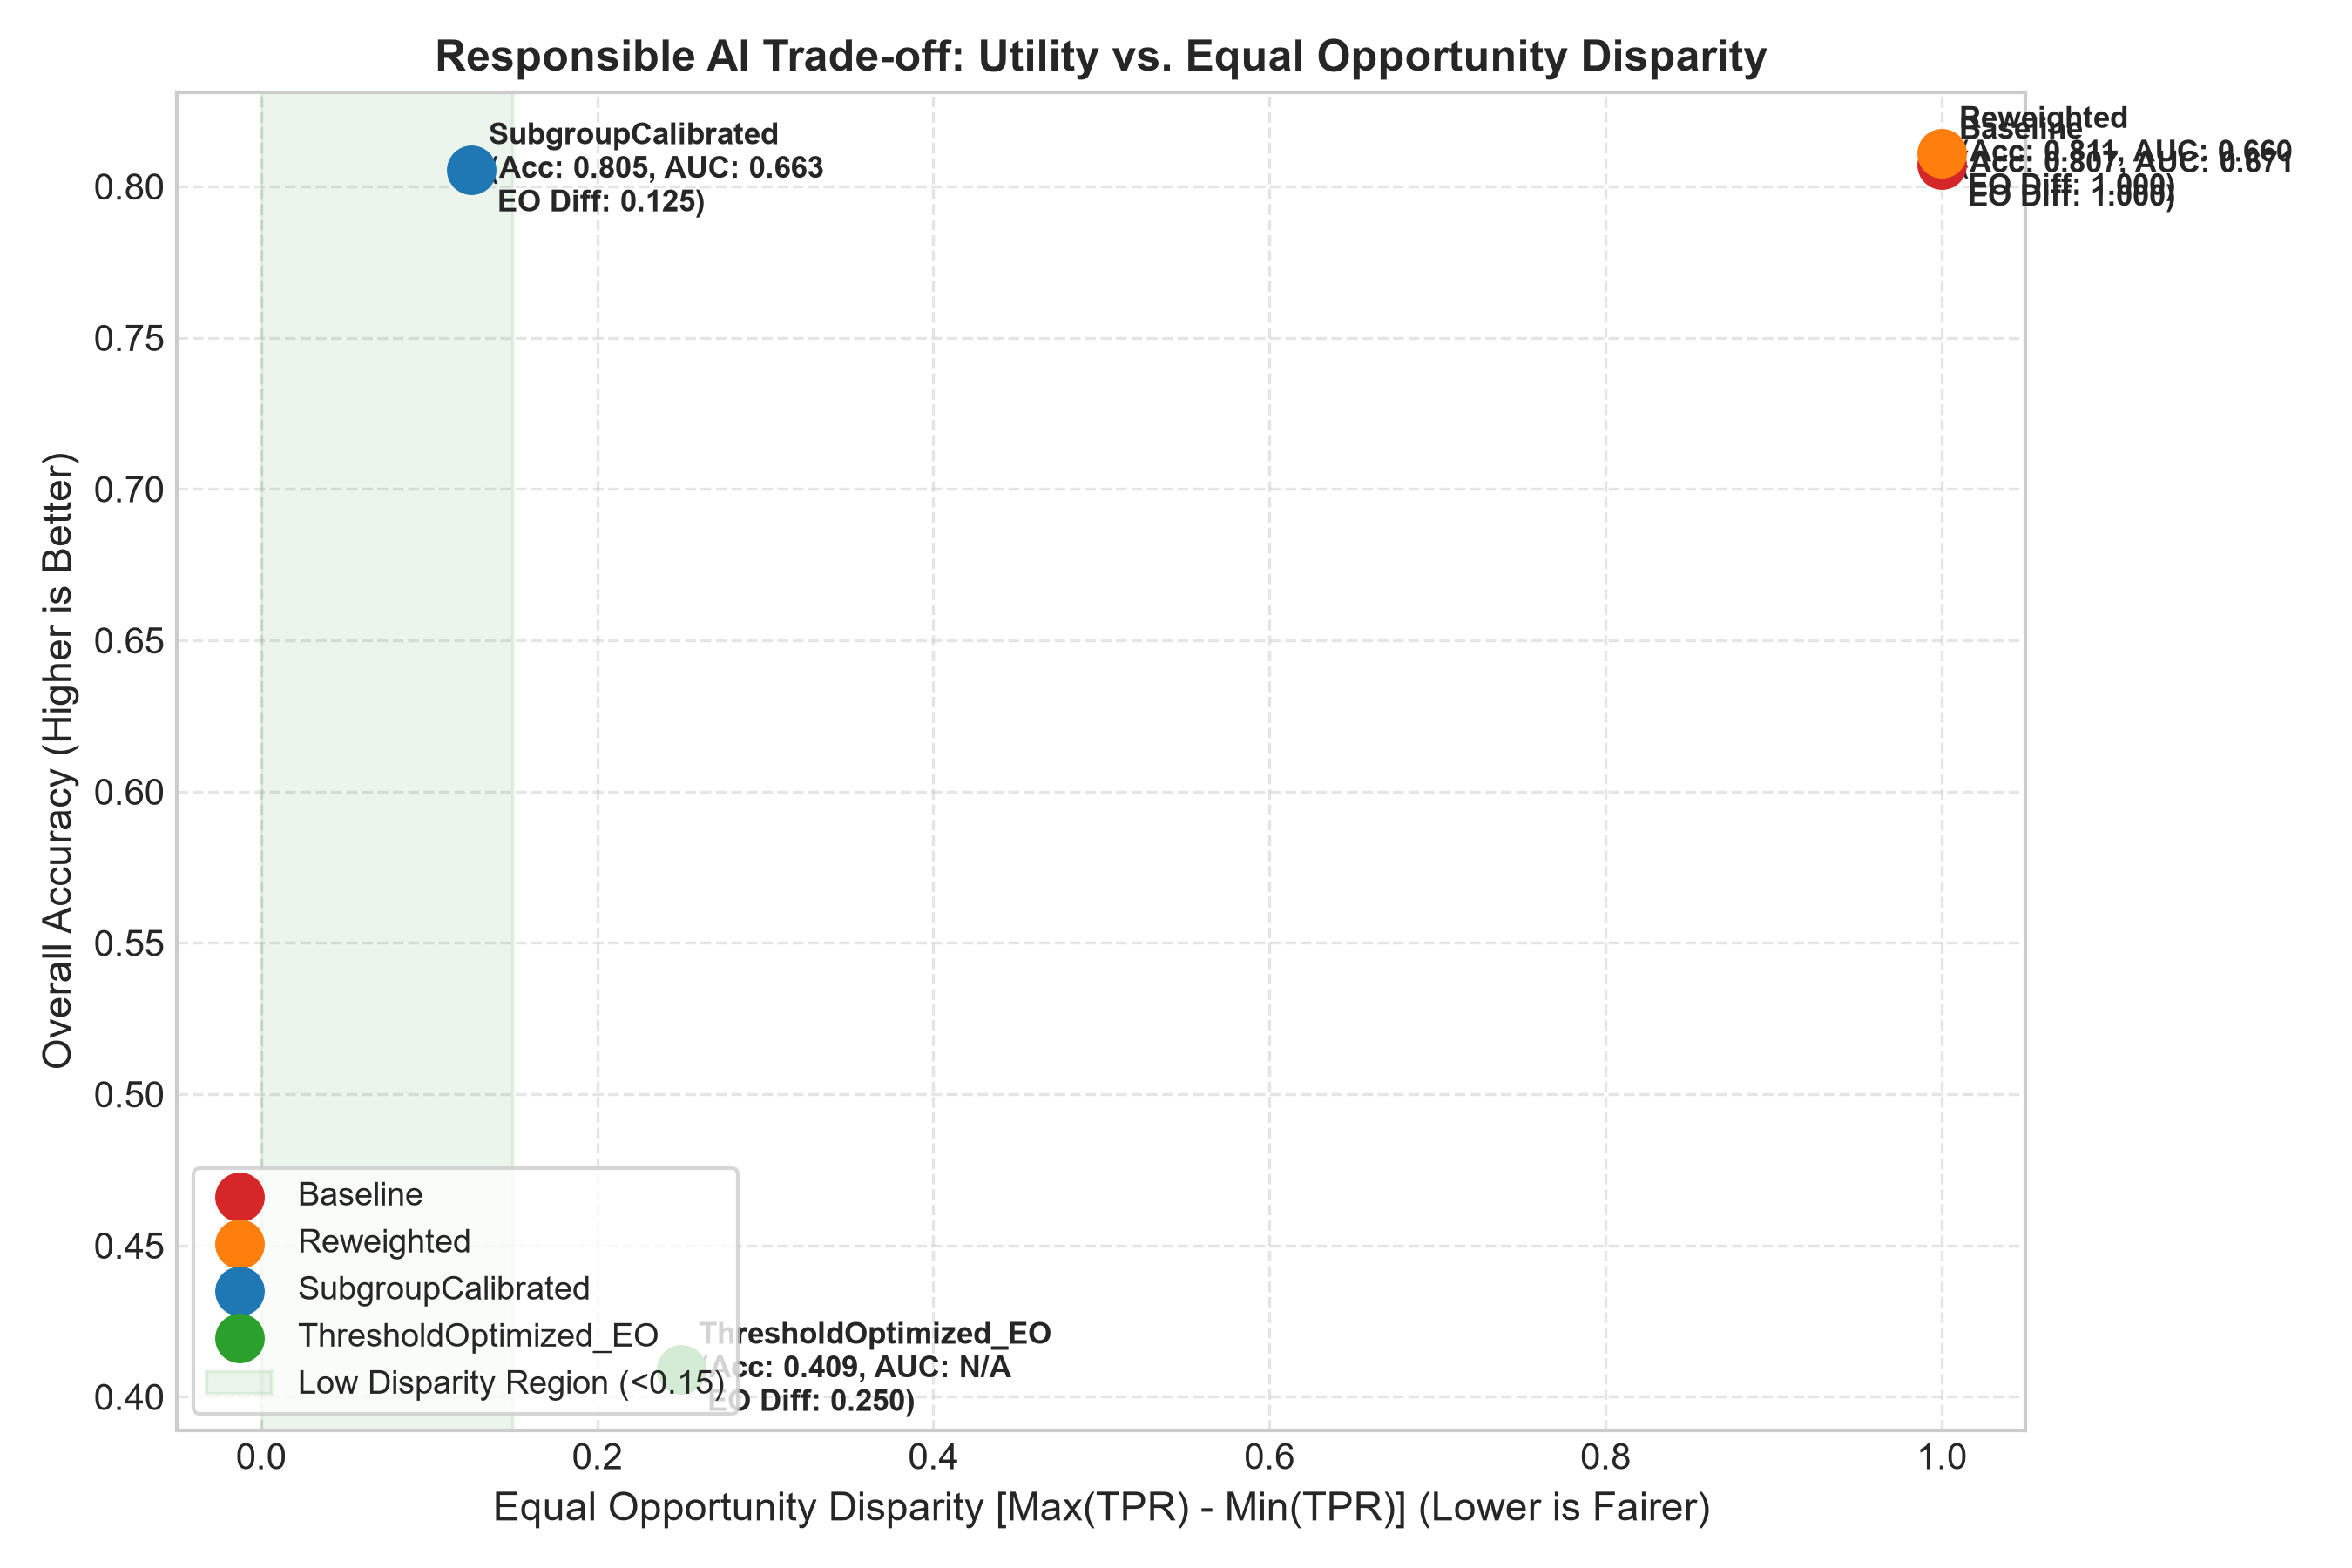

In [11]:
# Display Calibration Reliability Comparison and Fairness-Utility Pareto Frontier
display(Image(filename="../reports/figures/calibration_comparison.png"))
display(Image(filename="../reports/figures/fairness_utility_tradeoff.png"))

## 7. Big Data Scalability Evidence
Measured empirical benchmarks evaluating PySpark distributed ETL throughput, scaling latency, and Parquet compression ratio.

|    |   scale_n_patients |   raw_size_mb |   parquet_size_mb |   compression_ratio |   elapsed_seconds |   throughput_rec_per_sec |   memory_usage_mb |   cpu_cores |   system_ram_gb |
|----|--------------------|---------------|-------------------|---------------------|-------------------|--------------------------|-------------------|-------------|-----------------|
|  0 |               2500 |          5.52 |              0.19 |               29.7  |              7.24 |                    345.1 |              0.07 |          16 |            23.7 |
|  1 |               5000 |         10.92 |              0.23 |               47.14 |              6.43 |                    777.6 |              0    |          16 |            23.7 |
|  2 |              10000 |         22.16 |              0.34 |               66.01 |              6.79 |                   1472.3 |              0    |          16 |            23.7 |


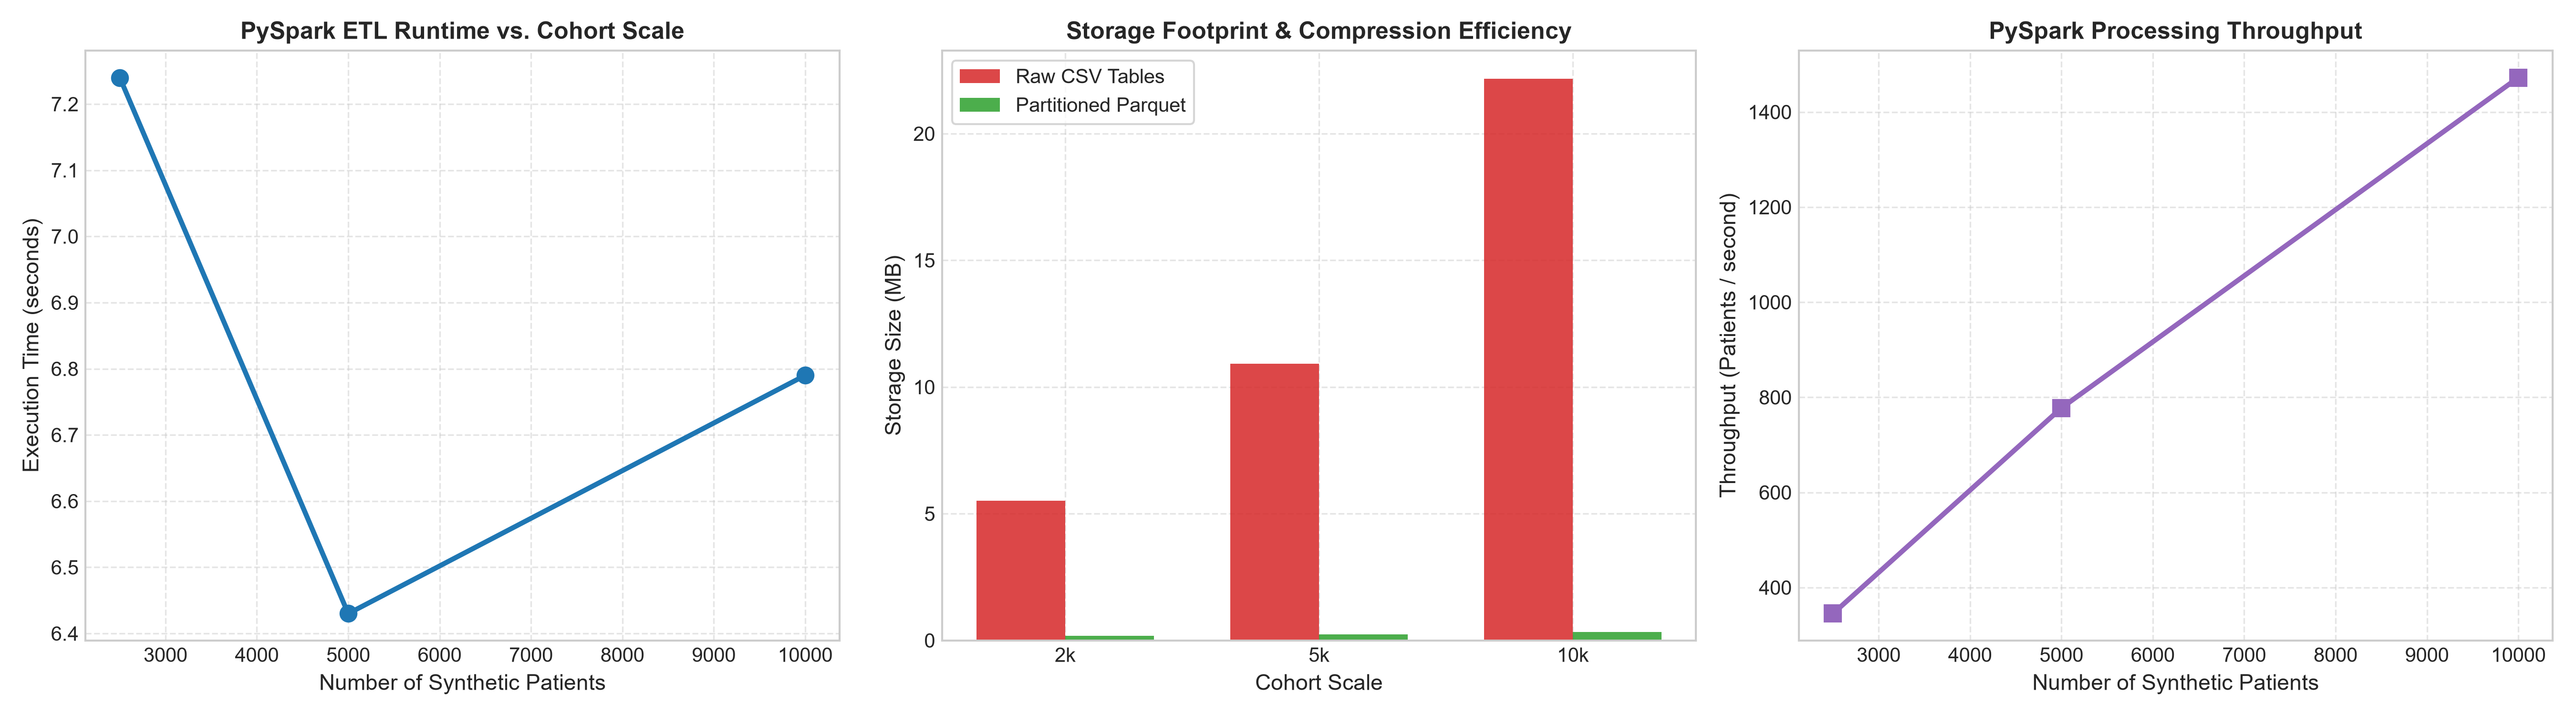

In [12]:
df_bench = pd.read_csv("../reports/figures/scalability_benchmark.csv")
print(tabulate(df_bench, headers="keys", tablefmt="github"))
display(Image(filename="../reports/figures/big_data_scaling.png"))